# How are in-demand skills trending for Data Analysts?

Methodology:
1. Aggregate skill counts monthly
2. Re-analyze based on percentage of total jobs
3. Plot the monthly skill demand

In [54]:
import ast
import pandas as pd
import seaborn as sns
from datasets import load_dataset
from matplotlib.ticker import PercentFormatter
import matplotlib.pyplot as plt

# Loading our data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

# Data cleanup
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

In [55]:
df_DA_RO = df[(df['job_title'] == 'Data Analyst') & (df['job_country'] == 'Romania')].copy()

In [56]:
df_DA_RO['job_posted_month_no'] = df_DA_RO['job_posted_date'].dt.month

In [57]:
df_DA_RO_explode = df_DA_RO.explode('job_skills')

In [58]:
df_DA_RO_pivot = df_DA_RO_explode.pivot_table(index='job_posted_month_no', columns='job_skills', aggfunc='size', fill_value=0)

df_DA_RO_pivot.loc['Total'] = df_DA_RO_pivot.sum()

df_DA_RO_pivot = df_DA_RO_pivot[df_DA_RO_pivot.loc['Total'].sort_values(ascending=False).index]

df_DA_RO_pivot = df_DA_RO_pivot.drop('Total')

df_DA_RO_pivot

job_skills,sql,excel,python,power bi,tableau,r,sap,powerpoint,vba,word,...,jenkins,ms access,plotly,scala,powershell,scikit-learn,ssrs,splunk,symphony,webex
job_posted_month_no,,,,,,,,,,,,,,,,,,,,,
1,14,8,10,8,5,5,4,1,8,2,...,0,0,0,0,0,0,0,0,1,1
2,13,5,6,7,6,5,0,1,0,2,...,0,0,0,0,0,0,0,0,0,0
3,8,7,5,6,4,6,6,1,0,1,...,0,0,0,1,0,0,0,0,0,0
4,6,10,4,5,4,3,1,4,1,4,...,0,0,0,0,0,0,0,0,0,0
5,7,11,4,8,4,2,3,5,0,2,...,0,0,0,0,0,0,1,0,0,0
6,3,5,1,1,0,0,1,0,1,1,...,0,0,0,0,0,0,0,0,0,0
7,3,9,2,1,0,0,1,4,1,1,...,0,0,0,0,0,0,0,1,0,0
8,8,6,5,2,2,3,2,1,2,1,...,0,0,0,0,0,0,0,0,0,0
9,7,4,5,4,2,2,2,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [59]:
DA_totals = df_DA_RO.groupby('job_posted_month_no').size()

In [60]:
df_DA_RO_perc = df_DA_RO_pivot.div(DA_totals, axis=0) * 100

df_DA_RO_perc = df_DA_RO_perc.reset_index()
df_DA_RO_perc['job_posted_month'] = df_DA_RO_perc['job_posted_month_no'].apply(lambda x: pd.to_datetime(x, format='%m').strftime('%b'))
df_DA_RO_perc.set_index('job_posted_month', inplace=True)
df_DA_RO_perc = df_DA_RO_perc.drop(columns='job_posted_month_no')

df_DA_RO_perc

job_skills,sql,excel,python,power bi,tableau,r,sap,powerpoint,vba,word,...,jenkins,ms access,plotly,scala,powershell,scikit-learn,ssrs,splunk,symphony,webex
job_posted_month,,,,,,,,,,,,,,,,,,,,,
Jan,70.000000,40.000000,50.000000,40.000000,25.000000,25.000000,20.000000,5.000000,40.000000,10.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,5.0,5.0
Feb,68.421053,26.315789,31.578947,36.842105,31.578947,26.315789,0.000000,5.263158,0.000000,10.526316,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.0,0.0
Mar,44.444444,38.888889,27.777778,33.333333,22.222222,33.333333,33.333333,5.555556,0.000000,5.555556,...,0.000000,0.000000,0.000000,5.555556,0.000000,0.000000,0.00,0.000000,0.0,0.0
Apr,33.333333,55.555556,22.222222,27.777778,22.222222,16.666667,5.555556,22.222222,5.555556,22.222222,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.0,0.0
May,43.750000,68.750000,25.000000,50.000000,25.000000,12.500000,18.750000,31.250000,0.000000,12.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.25,0.000000,0.0,0.0
Jun,37.500000,62.500000,12.500000,12.500000,0.000000,0.000000,12.500000,0.000000,12.500000,12.500000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.0,0.0
Jul,27.272727,81.818182,18.181818,9.090909,0.000000,0.000000,9.090909,36.363636,9.090909,9.090909,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,9.090909,0.0,0.0
Aug,57.142857,42.857143,35.714286,14.285714,14.285714,21.428571,14.285714,7.142857,14.285714,7.142857,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00,0.000000,0.0,0.0
Sep,46.666667,26.666667,33.333333,26.666667,13.333333,13.333333,13.333333,0.000000,0.000000,0.000000,...,0.000000,0.000000,6.666667,0.000000,0.000000,0.000000,0.00,0.000000,0.0,0.0


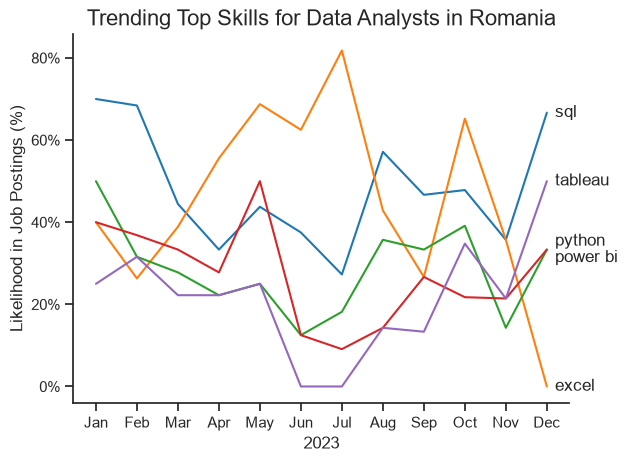

In [ ]:
df_plot = df_DA_RO_perc.iloc[:, :5]

sns.lineplot(data=df_plot, dashes=False, palette='tab10')
sns.set_theme(style='ticks')
sns.despine()

plt.title('Trending Top Skills for Data Analysts in Romania', fontsize=16)
plt.ylabel('Likelihood in Job Postings (%)')
plt.xlabel('2023')
plt.legend().remove()

ax = plt.gca()
ax.yaxis.set_major_formatter(PercentFormatter())

for i in range(5):
    y_val = df_plot.iloc[-1, i]
    label = df_plot.columns[i]
    
    if label == 'python':
        y_val += 2.0
    elif label == 'power bi':
        y_val -= 2.0
        
    plt.text(11.2, y_val, label, va='center')